# Semantic Segmentation

---

## Dataset Preparation

In [1]:
# Setup

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

data_dir = Path.cwd() / "data"

In [2]:
# Collecting image paths

records = []

for image_path in sorted(data_dir.glob("*/*.tif")):
    # Skipping masks, saving image and mask together
    if image_path.stem.endswith("_mask"):
        continue

    # Gettings mask patah from image name
    mask_path = image_path.with_name(f"{image_path.stem}_mask.tif")
    if not mask_path.is_file():
        raise FileNotFoundError(f"Missing mask: {mask_path}")

    records.append(
        {
            "patient_id": image_path.parent.name,  # Patient id is folder name i think
            "image_id": image_path.stem,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
        }
    )

In [3]:
# Converting to pandas

data_df = pd.DataFrame(records)
print(f"Number of patients: {data_df['patient_id'].nunique()}")
print(f"Number of image-mask pairs: {len(data_df)}")

display(data_df.head())

Number of patients: 110
Number of image-mask pairs: 3929


,patient_id,image_id,image_path,mask_path
0,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_1,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
1,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_10,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
2,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_11,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
3,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_12,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...
4,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_13,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...


In [4]:
# Inspecting images

# Grabbing first pair of images
sample = data_df.iloc[0]
with Image.open(sample["image_path"]) as image_file:
    image = np.array(image_file)
with Image.open(sample["mask_path"]) as mask_file:
    mask = np.array(mask_file)
    
print(f"Image shape: {image.shape}")
print(f"Image data type: {image.dtype}")
print(f"Image pixel range: {image.min()} to {image.max()}")

print(f"\nMask shape: {mask.shape}")
print(f"Mask data type: {mask.dtype}")
print(f"Unique mask values: {np.unique(mask)}")

Image shape: (256, 256, 3)
Image data type: uint8
Image pixel range: 0 to 215

Mask shape: (256, 256)
Mask data type: uint8
Unique mask values: [0]


In [5]:
# Identifying any images with abnormalities from masks
# If any white pixels in mask, abnormalities present

has_abnormality = []

for mask_path in data_df["mask_path"]:
    with Image.open(mask_path) as mask_file:
        mask = np.array(mask_file)
        
    has_abnormality.append(bool(np.any(mask > 0))) # If any are non zero
    
data_df["has_abnormality"] = has_abnormality

print(f"Masks with abnormalities found:    {data_df['has_abnormality'].sum()}")
print(f"Masks without abnormalities found: {(~data_df['has_abnormality']).sum()}")

Masks with abnormalities found:    1373
Masks without abnormalities found: 2556


In [6]:
# Final Dataset Inspection
# Images will be loaded from paths as needed for memory

display(data_df.head())
display(data_df.describe())

,patient_id,image_id,image_path,mask_path,has_abnormality
0,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_1,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,False
1,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_10,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,False
2,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_11,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,True
3,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_12,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,True
4,TCGA_CS_4941_19960909,TCGA_CS_4941_19960909_13,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,True


,patient_id,image_id,image_path,mask_path,has_abnormality
count,3929,3929,3929,3929,3929
unique,110,3929,3929,3929,2
top,TCGA_HT_A61A_20000127,TCGA_CS_4941_19960909_1,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,c:\dev\repos\Semantic Segmentation\data\TCGA_C...,False
freq,88,1,1,1,2556


## Data visualization

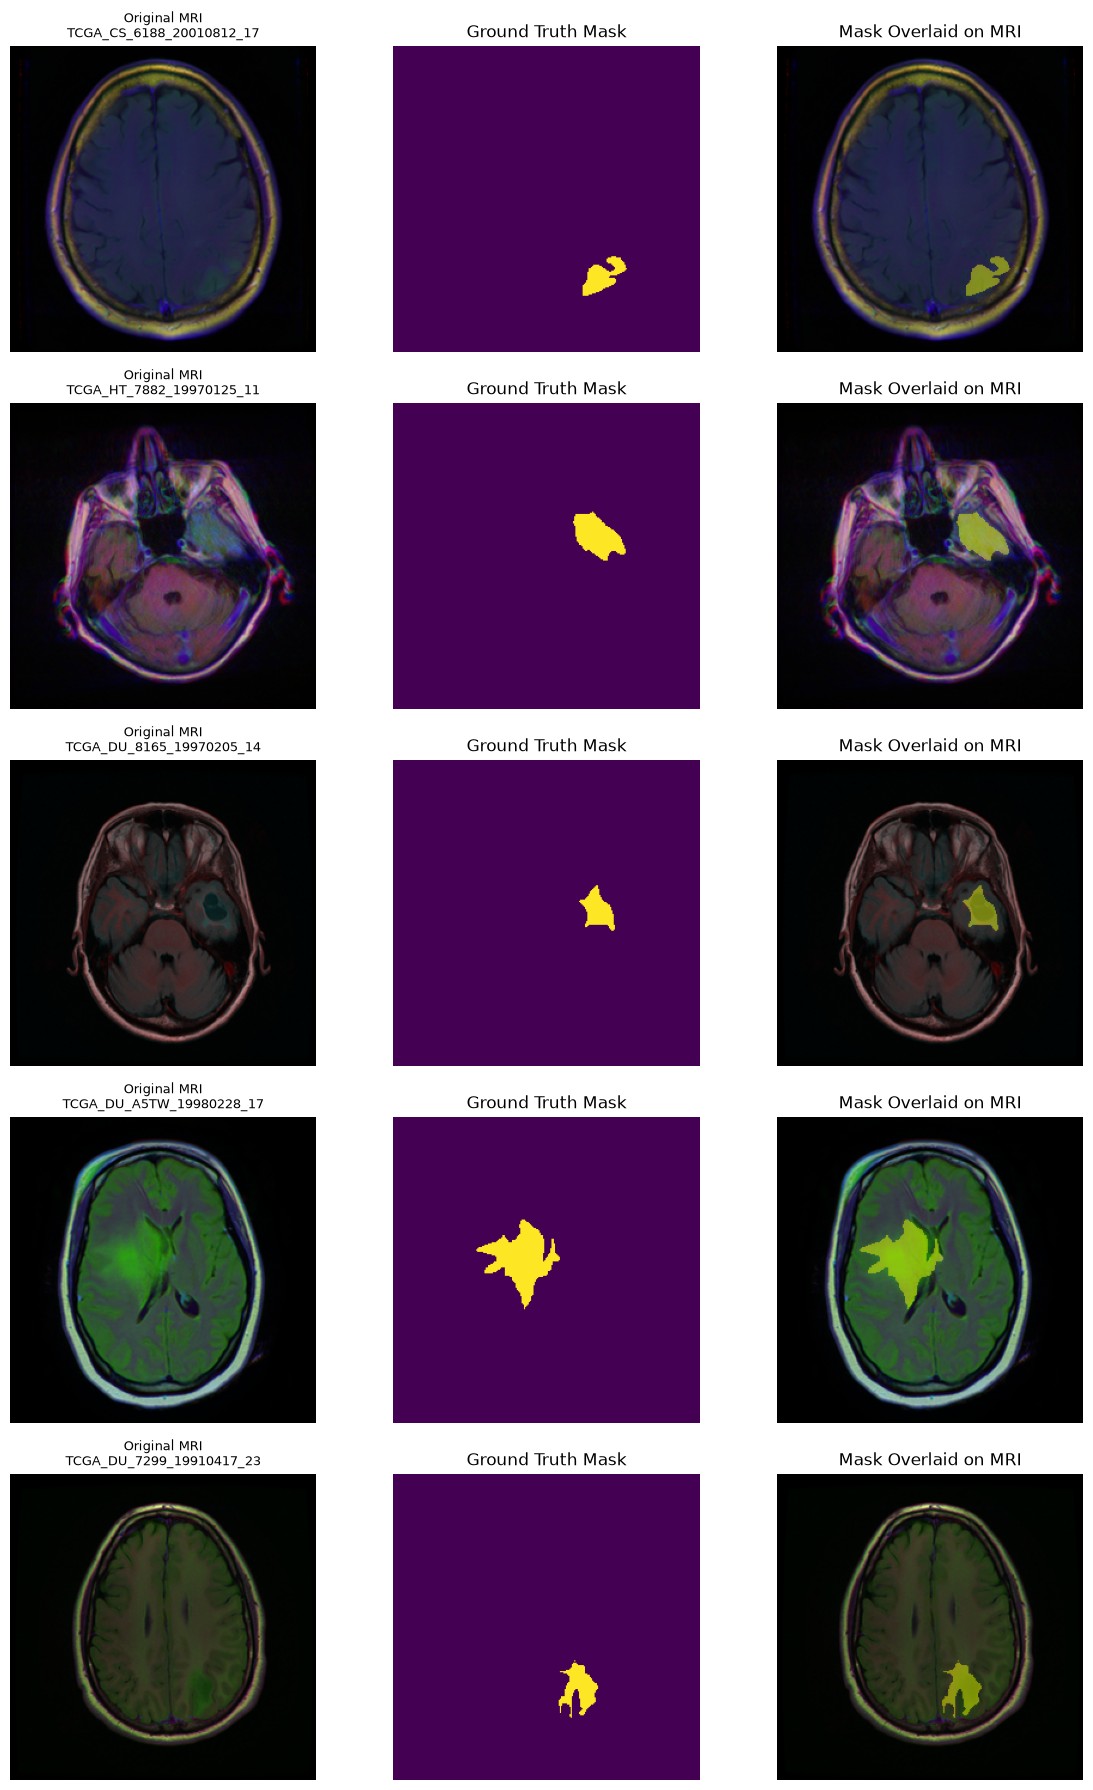

In [7]:
# Viewing images and their masks

# Getting all rows where mask has abnormality
abnormal_masks = data_df[data_df["has_abnormality"]]

examples = (
    abnormal_masks
    .groupby("patient_id", group_keys=False) # Group rows by patient
    .sample(n=1, random_state=24)            # Choose one mask from each patient
    .sample(n=5, random_state=24)            # Choose 5 masks from the last result
)

fig, axes = plt.subplots(5, 3, figsize=(12, 18))
for row_idx, (_, sample) in enumerate(examples.iterrows()):
    # Loading original images
    with Image.open(sample["image_path"]) as image_file:
        image = np.array(image_file)
    with Image.open(sample["mask_path"]) as mask_file:
            mask = np.array(mask_file)
            
    # Display original
    axes[row_idx, 0].imshow(image)
    axes[row_idx, 0].set_title(
        f"Original MRI\n{sample['image_id']}", fontsize=9
    )
    
    # Display mask
    axes[row_idx, 1].imshow(mask)
    axes[row_idx, 1].set_title("Ground Truth Mask")
    
    # Display overlaid
    
    # Hiding bg pixels so they don't cover image
    binary_mask = mask > 0
    overlay_mask = np.ma.masked_where(~binary_mask, binary_mask)
    
    axes[row_idx, 2].imshow(image)
    axes[row_idx, 2].imshow(
        overlay_mask,
        cmap="autumn",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[row_idx, 2].set_title("Mask Overlaid on MRI")
    
    for axis in axes[row_idx]:
        axis.axis("off")
        
plt.tight_layout()
plt.show()

## Dataset Preprocessing

## Model Design

## Model Training

## Model Evaluation